# HWM: hierarchical planning with latent world models

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/hwm.ipynb)

[HWM](https://arxiv.org/abs/2604.03208) ([code](https://github.com/kevinghst/HWM_PLDM)) stacks two world models in one latent space. The low level predicts the next latent from an action; the high level predicts the latent a few steps later, a *waypoint*, from a *macro-action* that summarizes the actions in between. To plan, the high level finds waypoints to the goal and the low level reaches the first one.

The task is PLDM's Two-Rooms, flown by a macaw: a rock wall splits the sky and the goal is on the other side, so the way there is through the gap.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import Macaw
from torch_world.models import HWM, LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM, HierarchicalPlanner
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
STRIDE, HISTORY = 4, 3  # one waypoint every 4 steps, 3 waypoints of context
WINDOW = HISTORY * STRIDE + 1

## Data
The macaw flies at random over the Pantanal, where a rock wall with one gap splits the sky in two, keeping its previous action 80% of the time. No rewards, no expert: just pixels and actions.

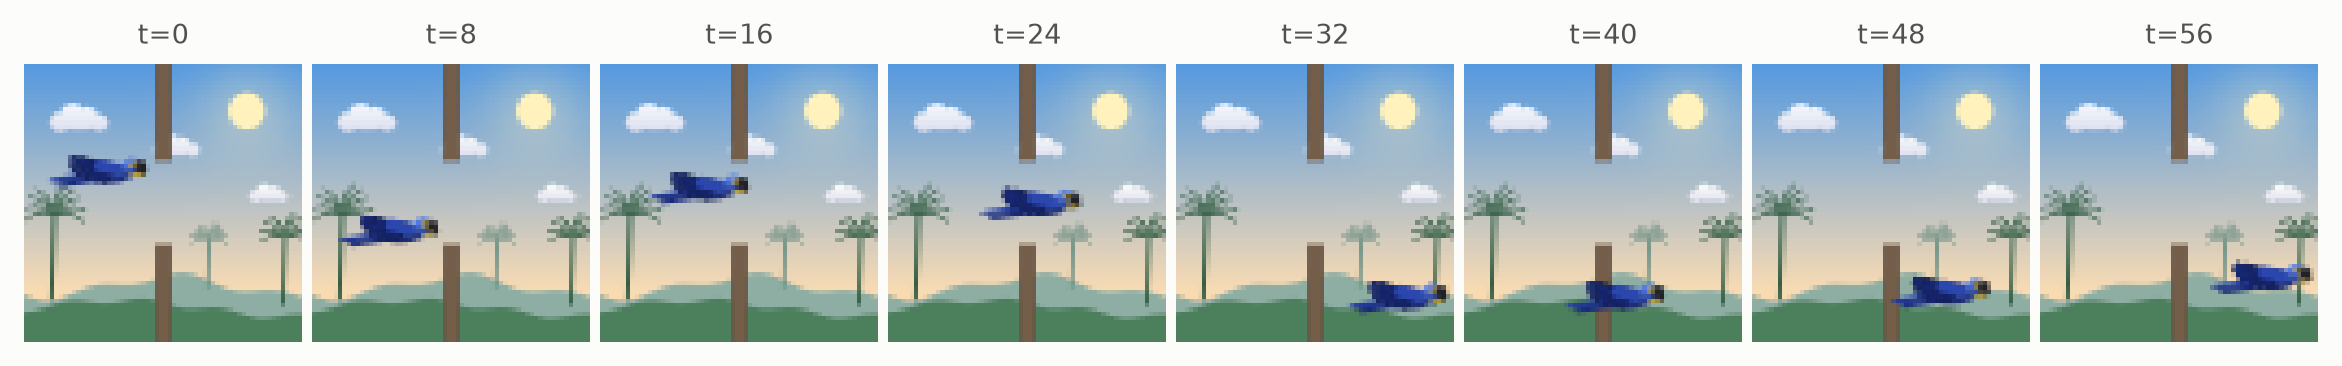

In [3]:
data = Macaw(batch_size=1024, rooms=True, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=WINDOW), batch_size=128, shuffle=True, drop_last=True)
plots.images(data["pixels"][0, :64:8].cpu(), [f"t={t}" for t in range(0, 64, 8)])

## Model
The low level is a small LeWM, learned from pixels. The high level is a second predictor over waypoint latents, conditioned on 8-d macro-actions that an MLP encodes from the 4 actions between waypoints.

In [4]:
encoder = CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
low = LeWM(encoder, action_dim=2, embed_dim=128, history=HISTORY, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512, lamb=0.05)
model = HWM(low, action_dim=2, stride=STRIDE, macro_dim=8, embed_dim=128, history=HISTORY, depth=4, num_heads=4, head_dim=32, mlp_dim=512).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

3.6M parameters


## Train
Both levels train at once with HWM's ℓ1 losses: teacher forcing at both levels and multi-step rollouts at the low level. SIGReg keeps the latents from collapsing; the high level sees them through a stop-gradient, as if the encoder were frozen.

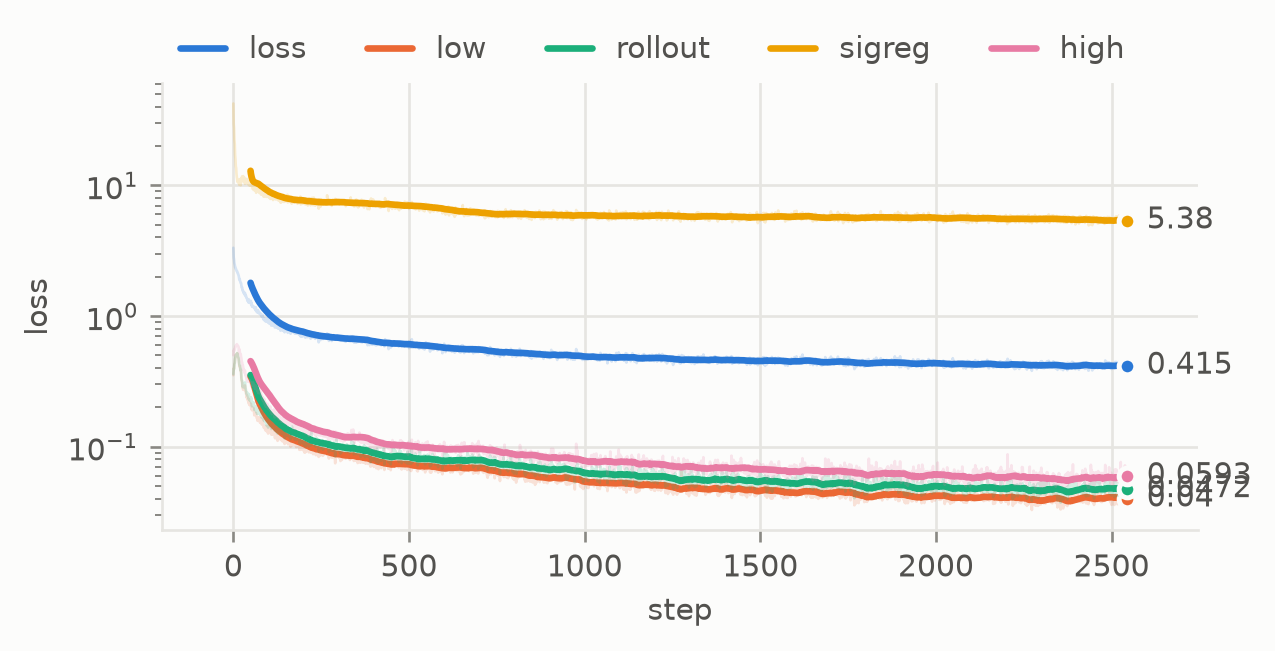

In [5]:
log = fit(model, loader, epochs=6)
plots.curves(log, smooth=50)

## Plan toward goal images across the wall
- **hierarchical**: CEM over 5 macro-actions (20 steps) toward the goal, then CEM over 4 actions toward the first waypoint;
- **flat**: CEM over 20 actions on the same model.

Both replan after every step.

In [6]:
env = Macaw(batch_size=32, rooms=True, device=device)
start, goal = env.tasks(generator=torch.Generator().manual_seed(1))  # start and goal on opposite sides of the wall
goal_images = env.render(goal)

hierarchical = HierarchicalPlanner(
    CEM(horizon=5, action_dim=8, num_samples=300, num_elites=30, bounds=(-2, 2)),
    CEM(horizon=STRIDE, action_dim=2, num_samples=256, num_elites=32, iterations=6, bounds=(-1, 1)),
)
flat = CEM(horizon=5 * STRIDE, action_dim=2, num_samples=300, num_elites=30, bounds=(-1, 1))

policies = {
    "hierarchical": evaluation.goal_policy(model, hierarchical, goal_images),
    "flat": evaluation.goal_policy(model, flat, goal_images),
    "random actions": evaluation.random_policy(env),
}
result = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
result

                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
hierarchical       22% [11%, 39%]      22%      19            0.26     0.471  0.0932       0.419   4.73e+03
flat               72% [55%, 84%]      72%    20.2           0.158     0.675   0.204       0.419   1.51e+04
random actions      16% [7%, 32%]      16%    19.6           0.525   -0.0593  0.0152        1.05     0.0881

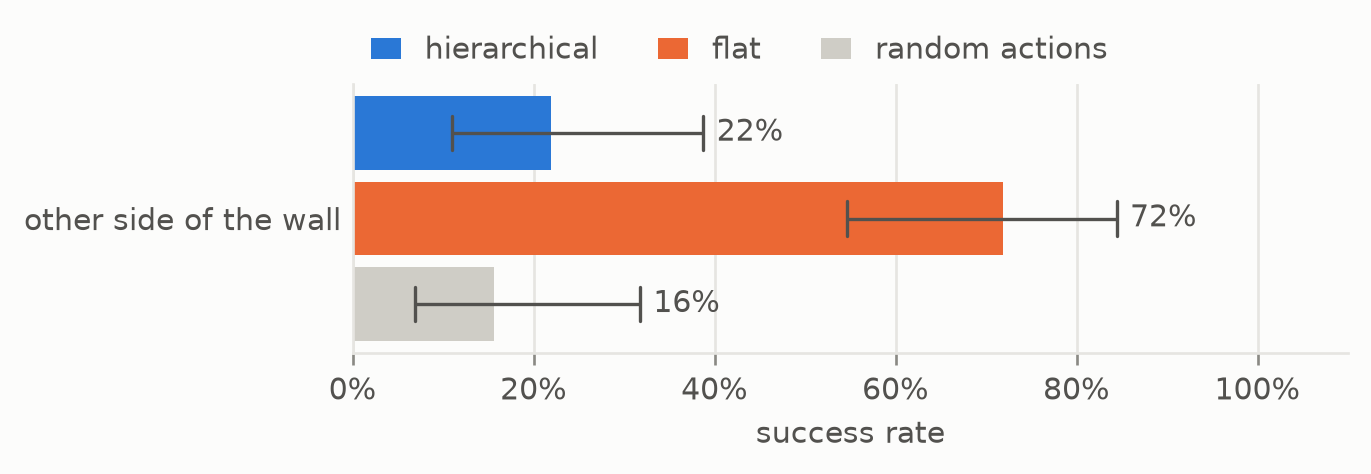

In [7]:
plots.bars({"other side of the wall": result.intervals()}, xlabel="success rate", baseline="random actions")

Paths of the hierarchical planner (top row) and the flat one (bottom row); the darker, the later:

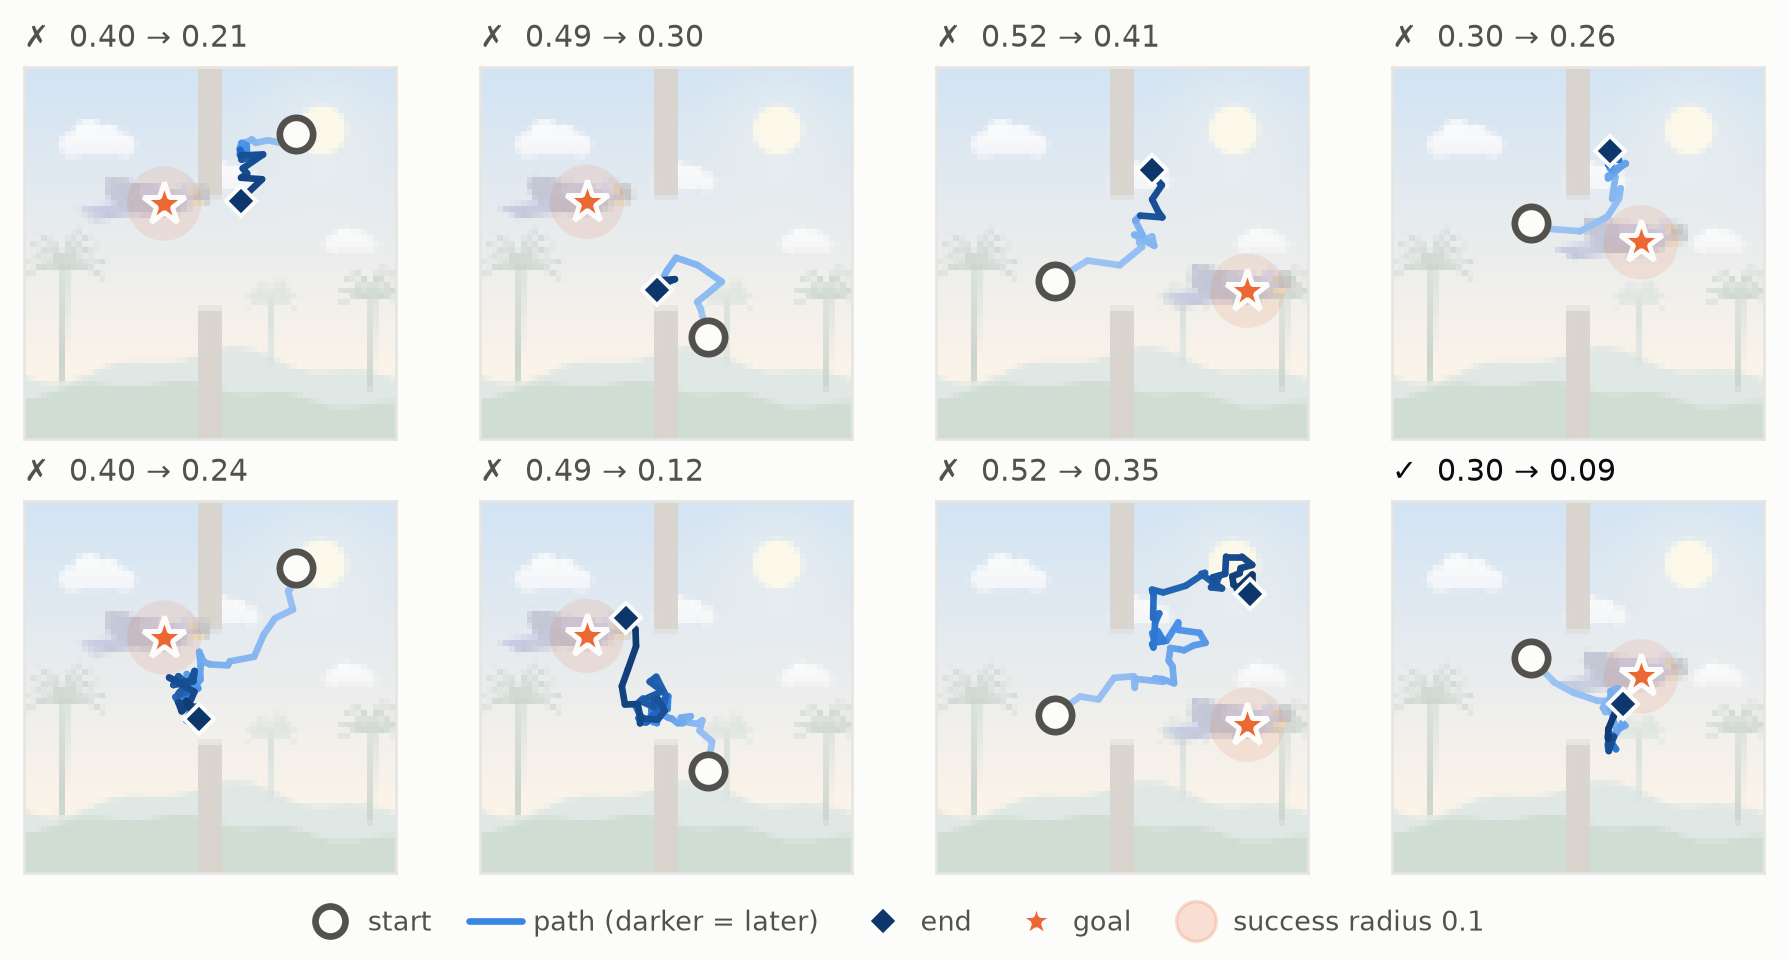

In [8]:
paths = torch.cat([result.paths["hierarchical"][:4], result.paths["flat"][:4]])
success = torch.cat([result.success["hierarchical"][:4], result.success["flat"][:4]])
plots.trajectories(paths, goal[:4].repeat(2, 1), radius=env.radius, background=goal_images[:4].repeat(2, 1, 1, 1), success=success)

## Summary
The high level plans in waypoints four steps apart, so 5 macro-actions span the 20 steps that the flat planner searches action by action. Differences from the paper: the encoder is learned with SIGReg instead of a frozen V-JEPA 2 or DINOv2, waypoints are evenly spaced, the macro-action encoder is an MLP, and both levels plan with CEM.